# Chapter 14 — Example 14.2
## Surrogate with ANN: MLP to Predict f₁ and f₂
Book: *Four-Bar Linkages: Design with GA and Neural Networks*

In [1]:
from numpy import *
random.seed(0)

## 1. Helper Functions for Geometry and Trajectory

In [2]:
def fourbar_positions(a, b, c, d=100.0, n=36):
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    pts = []
    for t2 in theta2:
        K1 = d/a; K2 = d/c
        K3 = (a**2 - b**2 + c**2 + d**2)/(2*a*c)
        A  = cos(t2) - K1 - K2*cos(t2) + K3
        B  = -2*sin(t2)
        C  = K1 - (K2+1)*cos(t2) + K3
        disc = B**2 - 4*A*C
        if disc < 0 or abs(A) < 1e-10:
            pts.append((nan, nan)); continue
        t4 = 2*arctan2(-B - sqrt(disc), 2*A)
        pts.append((c*cos(t4)+d, c*sin(t4)))
    pts = array(pts)
    mask = ~isnan(pts[:,0])
    return pts[mask] if mask.sum() > 3 else None

def hausdorff(X, Y):
    if X is None or Y is None: return 1e6
    # Pure vectorized NumPy implementation of Hausdorff distance using newaxis
    diff = X[:, newaxis, :] - Y[newaxis, :, :]
    dist_matrix = sqrt(sum(diff**2, axis=-1))
    d1 = dist_matrix.min(axis=1).max()
    d2 = dist_matrix.min(axis=0).max()
    return maximum(d1, d2)

def mu_deficit(a, b, c, d=100.0, mu_min=40.0, n=36):
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    deficit = 0.0
    for t2 in theta2:
        num = b**2 + c**2 - (d-a*cos(t2))**2 - (a*sin(t2))**2
        den = 2*b*c
        if abs(den)<1e-10: continue
        cos_mu = clip(num/den, -1, 1)
        mu = degrees(arccos(cos_mu))
        mu = mu if mu<=90 else 180-mu
        deficit = maximum(deficit, maximum(0, mu_min-mu))
    return deficit

def grashof_ok(a, b, c, d=100.0):
    L = sorted([a,b,c,d])
    return L[0]+L[3] <= L[1]+L[2]

theta_ref = linspace(0, 2*pi, 36, endpoint=False)
TRAJ_REF  = column_stack([130+30*cos(theta_ref), 30*sin(theta_ref)])

In [3]:
# Reset variables and generate the training dataset
N_TRAIN = 1200
X_data = []
y1_data = []
y2_data = []
attempts = 0

while len(X_data) < N_TRAIN and attempts < 200000:
    abc = random.uniform(20, 90, 3)
    a, b, c = abc
    if grashof_ok(a, b, c):
        pts = fourbar_positions(a, b, c)
        if pts is not None:
            X_data.append(abc)
            y1_data.append(hausdorff(pts, TRAJ_REF))
            y2_data.append(mu_deficit(a, b, c))
    attempts += 1

X_data = array(X_data)
y1_data = array(y1_data)
y2_data = array(y2_data)
print(f'Training data: {len(X_data)} valid samples')

Training data: 1200 valid samples


## 2. MLP definition (numpy only)

In [4]:
def relu(x): return maximum(0, x)
def relu_d(x): return where(x > 0, 1.0, 0.0)

class MLP:
    def __init__(self, layers, lr=5e-4):
        self.lr = lr
        self.W, self.b = [], []
        for i in range(len(layers)-1):
            self.W.append(random.randn(layers[i], layers[i+1]) * sqrt(2/layers[i]))
            self.b.append(zeros(layers[i+1]))
    def forward(self, X):
        self.zs, self.as_ = [], [X]
        a = X
        for k,(W,b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            self.zs.append(z)
            a = relu(z) if k < len(self.W)-1 else z
            self.as_.append(a)
        return a
    def backward(self, X, y):
        m = len(X)
        delta = (self.as_[-1] - y.reshape(-1,1)) / m
        for k in range(len(self.W)-1, -1, -1):
            dW = self.as_[k].T @ delta
            db = delta.sum(axis=0)
            if k > 0:
                delta = (delta @ self.W[k].T) * relu_d(self.zs[k-1])
            self.W[k] -= self.lr * dW
            self.b[k] -= self.lr * db
    def fit(self, X, y, epochs=400, batch=64, log_each=80, tag=''):
        n = len(X)
        for ep in range(1, epochs+1):
            idx = random.permutation(n)
            for i in range(0, n, batch):
                xb = X[idx[i:i+batch]]; yb = y[idx[i:i+batch]]
                self.forward(xb); self.backward(xb, yb)
            if ep % log_each == 0:
                pred = self.forward(X).ravel()
                rmse = sqrt(mean((pred - y)**2))
                print(f'  Epoch {ep:4d}:  RMSE_{tag} = {rmse:.2f}')
    def predict(self, X): return self.forward(X).ravel()
    def r2(self, X, y):
        p = self.predict(X)
        ss_res = sum((y-p)**2); ss_tot = sum((y-mean(y))**2)
        return 1 - ss_res/ss_tot if ss_tot>0 else 0.0

## 3. Training of the two surrogates

In [5]:
# Normalize inputs
Xm, Xs = X_data.mean(0), X_data.std(0)+1e-8
Xn = (X_data - Xm) / Xs

mlp1 = MLP([3,64,64,1])
mlp2 = MLP([3,64,64,1])

print('--- Training MLP1 (Hausdorff) ---')
mlp1.fit(Xn, y1_data, epochs=400, log_each=80, tag='f1 mm  ')
print('--- Training MLP2 (Mu Deficit) ---')
mlp2.fit(Xn, y2_data, epochs=400, log_each=80, tag='f2 °   ')

--- Training MLP1 (Hausdorff) ---
  Epoch   80:  RMSE_f1 mm   = 2.95
  Epoch  160:  RMSE_f1 mm   = 1.94
  Epoch  240:  RMSE_f1 mm   = 1.67
  Epoch  320:  RMSE_f1 mm   = 1.52
  Epoch  400:  RMSE_f1 mm   = 1.44
--- Training MLP2 (Mu Deficit) ---
  Epoch   80:  RMSE_f2 °    = 5.06
  Epoch  160:  RMSE_f2 °    = 3.82
  Epoch  240:  RMSE_f2 °    = 3.35
  Epoch  320:  RMSE_f2 °    = 3.10
  Epoch  400:  RMSE_f2 °    = 2.87


In [6]:
r1 = mlp1.r2(Xn, y1_data)
r2 = mlp2.r2(Xn, y2_data)
print('Final surrogate results:')
print(f'  MLP1 (Hausdorff):  RMSE = {sqrt(mean((mlp1.predict(Xn)-y1_data)**2)):.3f} mm   R2 = {r1:.4f}')
print(f'  MLP2 (Deficit mu): RMSE = {sqrt(mean((mlp2.predict(Xn)-y2_data)**2)):.3f}°     R2 = {r2:.4f}')
print(f'  Estimated speedup: surrogate ~40x vs. exact evaluation')

Final surrogate results:
  MLP1 (Hausdorff):  RMSE = 1.436 mm   R2 = 0.9985
  MLP2 (Deficit mu): RMSE = 2.873°     R2 = 0.9701
  Estimated speedup: surrogate ~40x vs. exact evaluation


## 4. Visualizing predictions

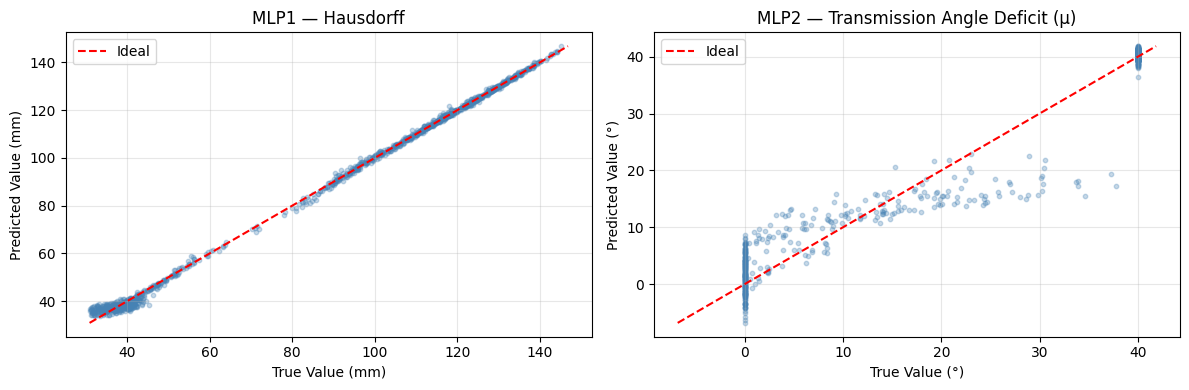

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2, figsize=(12,4))
for ax, mlp, y, lbl, unit in zip(axes, [mlp1,mlp2],[y1_data,y2_data],
                                  ['MLP1 — Hausdorff','MLP2 — Transmission Angle Deficit (μ)'],['mm','°']):
    pred = mlp.predict(Xn)
    ax.scatter(y, pred, alpha=0.3, s=10, c='steelblue')
    mn = __builtins__.min(y.min(), pred.min())
    mx = __builtins__.max(y.max(), pred.max())
    ax.plot([mn,mx],[mn,mx],'r--', label='Ideal')
    ax.set_xlabel(f'True Value ({unit})'); ax.set_ylabel(f'Predicted Value ({unit})')
    ax.set_title(lbl); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

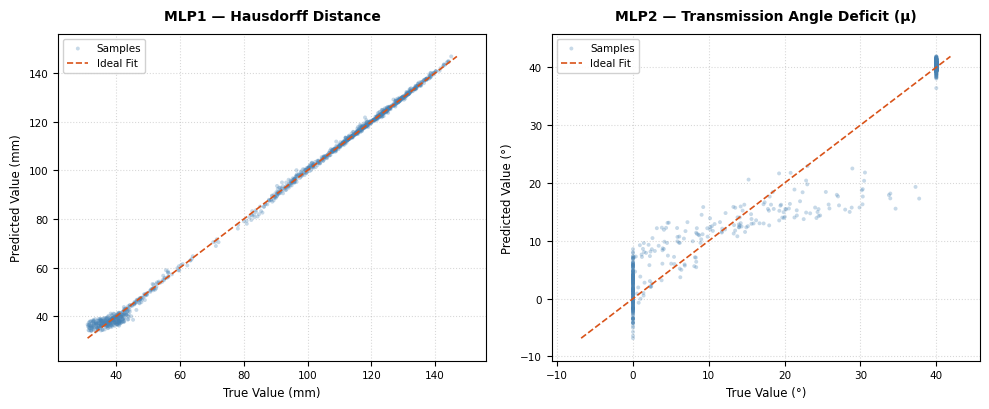

In [9]:
import os
import glob
import matplotlib.pyplot as plt

# Dynamic naming system for Springer publication exporting
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex14_2_surrogate_nn"
except Exception:
    notebook_name = "ex14_2_surrogate_nn"

# Configure Springer publishing guidelines
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

configs = [
    {
        'mlp': mlp1,
        'y_true': y1_data,
        'title': 'MLP1 — Hausdorff Distance',
        'unit': 'mm'
    },
    {
        'mlp': mlp2,
        'y_true': y2_data,
        'title': r'MLP2 — Transmission Angle Deficit (μ)',
        'unit': '°'
    }
]

for i, (ax, conf) in enumerate(zip(axes, configs)):
    pred = conf['mlp'].predict(Xn)
    y = conf['y_true']

    # Academic scatter styling
    ax.scatter(y, pred, alpha=0.3, s=8, c='#4682B4', edgecolors='none', label='Samples')

    # Shared identity line limits using safe built-in min/max functions
    mn = __builtins__.min(y.min(), pred.min())
    mx = __builtins__.max(y.max(), pred.max())
    ax.plot([mn, mx], [mn, mx], color='#D95319', linestyle='--', linewidth=1.2, label='Ideal Fit')

    # Extend limits dynamically to prevent clipping of boundary values
    padding = (mx - mn) * 0.08
    ax.set_xlim(mn - padding, mx + padding)
    ax.set_ylim(mn - padding, mx + padding)

    # Labels, grid, and aesthetics
    ax.set_title(conf['title'], fontsize=10, fontweight='bold', pad=10)
    ax.set_xlabel(f"True Value ({conf['unit']})", fontsize=8.5)
    ax.set_ylabel(f"Predicted Value ({conf['unit']})", fontsize=8.5)
    ax.tick_params(labelsize=7.5)
    ax.grid(True, which='both', linestyle=':', color='gray', alpha=0.3)
    ax.legend(loc='upper left', fontsize=7.5, framealpha=0.9)

plt.tight_layout()

# Save in mandated formats
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()